In [1]:
import numpy as np
from invlap import invlap
import matplotlib.pyplot as plt

In [2]:
import numpy as np

def ADE_sol(ts, xs, v, D):
    """
    Solves the advection-diffusion equation
    ts = Array. Times after release
    xs = Array. Distance from the point of release
    v = Float. Advection velocity
    D = Float. Diffusion coefficient
    """
    def sol_lap_space(s, x):
        Delta =  np.sqrt(v**2+4*D*s)/(2*D)
        alpha_plus = (v + np.sqrt(v**2+4*D*s))/(2*D)
        alpha_minus = (v - np.sqrt(v**2+4*D*s))/(2*D)
        # U = (alpha_minus*np.exp(alpha_minus+alpha_plus*x)-alpha_plus*np.exp(alpha_plus+alpha_minus*x))/(s*(alpha_minus*np.exp(alpha_minus)-alpha_plus*np.exp(alpha_plus))) #This doesn't work due to very large exponentials, we subtract Delta from all exponentials to remove this issue
        U = (alpha_minus*np.exp(alpha_minus+alpha_plus*x-Delta)-alpha_plus*np.exp(alpha_plus+alpha_minus*x-Delta))/(s*(alpha_minus*np.exp(alpha_minus-Delta)-alpha_plus*np.exp(alpha_plus-Delta)))
        return U
    u = np.array([invlap(sol_lap_space, ts, [x]) for x in xs])
    return u

In [3]:
Nt = 200
Nx = 200
ts = np.linspace(0,1,Nt+1)
xs = np.linspace(0,1,Nx+1)
v = 0.213*805/86
D = 0.037*805/86**2
ref_u = np.zeros((Nt+1,Nx+1))
ref_u[1:] = ADE_sol(ts[1:], xs, v, D).T
ref_u = np.nan_to_num(ref_u,nan = 0.0)

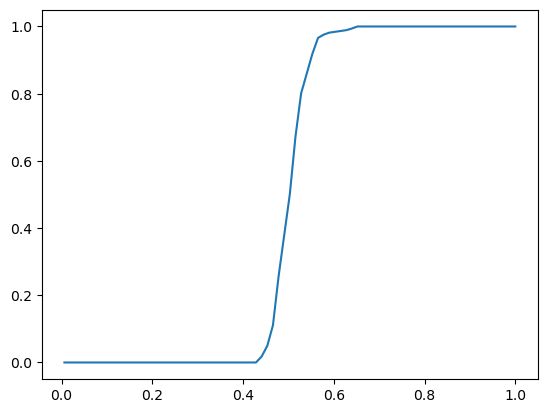

In [4]:
berkowitz_data = np.genfromtxt('homo1.txt', delimiter=',', skip_header=1)
data_t = berkowitz_data[:,0]/berkowitz_data[-1,0]
data_vals = berkowitz_data[:,1]
plt.plot(data_t,data_vals)

In [5]:
%%time
import torch
import torch.nn as nn
from torchinfo import summary
import random
from scipy.stats import qmc
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)


# =========================================================
# Device
# =========================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =========================================================
# Physical parameters
# =========================================================
v = 0.213*805/86
D = 0.037*805/86**2
Nt = 200
Nx = 200
lambda_PDE = 1.0

# Domain
x_min, x_max = 0.0, 1.0
t_min, t_max = 0.0, 1.0

# =========================================================
# PINN architecture
# =========================================================
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 84),
            nn.Tanh(),
            nn.Linear(84, 84),
            nn.Tanh(),
            nn.Linear(84, 1)
        )

    def forward(self, x, t):
        xt = torch.cat([x, t], dim=1)
        return self.net(xt)

model = PINN().to(device)
summary(model, input_size=[(1,1), (1,1)], device=device)
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
print(f"Trainable parameters: {trainable_params:,}")


# =========================================================
# PDE residual
# =========================================================
def pde_residual(x, t, v, D, model):
    x.requires_grad_(True)
    t.requires_grad_(True)

    u = model(x, t)

    u_x = torch.autograd.grad(
        u, x, grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_t = torch.autograd.grad(
        u, t, grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xx = torch.autograd.grad(
        u_x, x, grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    return u_t + v * u_x - D * u_xx

def rbc_res(x, t, model):
    x.requires_grad_(True)
    t.requires_grad_(True)

    u = model(x, t)

    u_x = torch.autograd.grad(
        u, x, grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    return u_x

# =========================================================
# Loss function
# =========================================================
def compute_loss(
    x_pde, t_pde,
    x_ic, t_ic, u_ic_true,
    x_bc_l, t_bc_l, u_bc_l_true,
    x_bc_r, t_bc_r, u_bc_r_true,
    v, D, model
):
    pde_res = pde_residual(x_pde, t_pde, v, D, model)
   
    loss_pde =  torch.mean(pde_res**2)

    loss_ic = torch.mean((model(x_ic, t_ic) - u_ic_true)**2)
    loss_bc_l = torch.mean((model(x_bc_l, t_bc_l) - u_bc_l_true)**2)
    loss_bc_r = torch.mean((rbc_res(x_bc_r, t_bc_r, model) - u_bc_r_true)**2)

    total_loss = lambda_PDE *loss_pde + loss_ic + loss_bc_l + loss_bc_r

    return total_loss, loss_pde, loss_ic, 10*loss_bc_l, loss_bc_r

# =========================================================
# Training points
# =========================================================
N_pde, N_ic, N_bc = 20000, 500, 1000

def rand_uniform(n, a, b):
    return (a + (b - a) * torch.rand(n, 1)).to(device)

t_ic = torch.full((N_ic,1), t_min, device=device)
u_ic_true = torch.zeros_like(t_ic)

x_bc_l = torch.full((N_bc//2,1), x_min, device=device)
u_bc_l_true = torch.ones_like(x_bc_l)

x_bc_r = torch.full((N_bc//2,1), x_max, device=device)
u_bc_r_true = torch.zeros_like(x_bc_r)

# =========================================================
# Evaluation grid
# =========================================================
x_eval = np.linspace(x_min, x_max, Nx+1)
t_eval = np.linspace(t_min, t_max, Nt+1)

X_eval, T_eval = np.meshgrid(x_eval, t_eval)
Xf = X_eval.flatten().reshape(-1,1)
Tf = T_eval.flatten().reshape(-1,1)

Xf_t = torch.tensor(Xf, dtype=torch.float32, device=device)
Tf_t = torch.tensor(Tf, dtype=torch.float32, device=device)

@torch.no_grad()
def eval_mse(model):
    u_pred = model(Xf_t, Tf_t).cpu().numpy().flatten()
    return np.mean((u_pred - ref_u.flatten())**2)

# =========================================================
# Training
# =========================================================
epochs = 1250000
optimizer = torch.optim.Adam(model.parameters(), lr=2.5e-3)
# scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
#     optimizer, T_max=epochs, eta_min=1e-3
# )
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, (0.9)**(1/12000))


loss_hist, eval_hist = [], []
losses_hist = []

def lhs_timespace(N, x_min, x_max, t_min, t_max, seed):
    sampler = qmc.LatinHypercube(d=2, seed=seed)
    sample = sampler.random(N)

    sample[:, 0] = x_min + (x_max - x_min) * sample[:, 0]
    sample[:, 1] = t_min + (t_max - t_min) * sample[:, 1]

    x = torch.tensor(sample[:, 0:1], dtype=torch.float32, device=device)
    t = torch.tensor(sample[:, 1:2], dtype=torch.float32, device=device)

    return x, t


for epoch in range(epochs):
    optimizer.zero_grad()
    if epoch==0:
        x_pde, t_pde = lhs_timespace(N_pde, x_min, x_max, t_min, t_max, seed+epoch)
        x_ic = rand_uniform(N_ic, x_min, x_max)
        t_bc_l = rand_uniform(N_bc//2, t_min, t_max)
        t_bc_r = rand_uniform(N_bc//2, t_min, t_max)

    total_loss, lpde, lic, lbl, lbr = compute_loss(
        x_pde, t_pde,
        x_ic, t_ic, u_ic_true,
        x_bc_l, t_bc_l, u_bc_l_true,
        x_bc_r, t_bc_r, u_bc_r_true,
        v, D, model
    )

    total_loss.backward()
    optimizer.step()
    scheduler.step()
    loss_hist.append(total_loss.item())

    
    e = eval_mse(model)
    eval_hist.append(e)
    losses_hist.append([lpde.item(), lic.item(), lbl.item(), lbr.item()])
    if epoch%100 == 0:
        print(
            f"Epoch {epoch:4d}, "
            f"{lpde.item():.3e}, {lic.item():.3e}, "
            f"{lbl.item():.3e}, {lbr.item():.3e} | "
            f"Total {total_loss.item():.3e} | Eval MSE {e:.3e}"
        )

Using device: cuda
Trainable parameters: 7,477


C:\Users\Manuel\Anaconda3\envs\torch_cuda\lib\site-packages\torch\autograd\graph.py:825: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\cuda\CublasHandlePool.cpp:135.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch    0, 3.275e-03, 2.185e-05, 8.735e+00, 3.303e-04 | Total 8.772e-01 | Eval MSE 3.295e-01
Epoch  100, 2.968e-02, 5.160e-02, 8.162e-01, 1.711e-02 | Total 1.800e-01 | Eval MSE 9.225e-02
Epoch  200, 3.064e-02, 3.899e-02, 5.186e-01, 5.350e-03 | Total 1.268e-01 | Eval MSE 6.180e-02
Epoch  300, 2.807e-02, 2.897e-02, 3.748e-01, 9.188e-03 | Total 1.037e-01 | Eval MSE 4.415e-02
Epoch  400, 3.067e-02, 2.450e-02, 3.678e-01, 3.552e-03 | Total 9.550e-02 | Eval MSE 3.905e-02
Epoch  500, 2.452e-02, 2.374e-02, 3.240e-01, 3.847e-03 | Total 8.451e-02 | Eval MSE 3.541e-02
Epoch  600, 2.388e-02, 2.202e-02, 2.995e-01, 3.436e-03 | Total 7.929e-02 | Eval MSE 3.252e-02
Epoch  700, 2.370e-02, 2.055e-02, 2.851e-01, 2.656e-03 | Total 7.541e-02 | Eval MSE 3.048e-02
Epoch  800, 2.373e-02, 1.955e-02, 2.708e-01, 2.287e-03 | Total 7.264e-02 | Eval MSE 2.871e-02
Epoch  900, 2.369e-02, 1.889e-02, 2.578e-01, 2.002e-03 | Total 7.036e-02 | Eval MSE 2.731e-02
Epoch 1000, 2.357e-02, 1.850e-02, 2.454e-01, 2.210e-03 | Tot

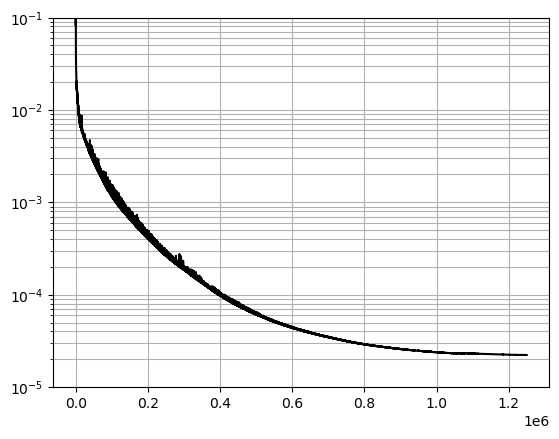

In [6]:
def simple_moving_average(data, window_size):
    weights = np.ones(window_size) / window_size
    return np.convolve(data, weights, mode='valid')
    
window_size = 1
plt.semilogy(simple_moving_average(eval_hist,window_size),c = 'k')
# for i in range(4):
    # plt.semilogy(simple_moving_average(np.array(losses_hist)[:,i],window_size),alpha = 0.8)
plt.ylim(1e-5,0.1)
plt.grid(which = 'both')

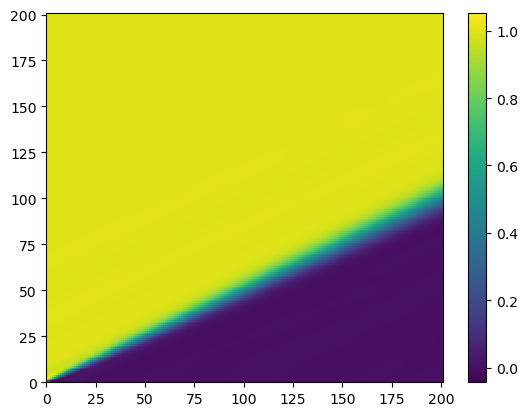

In [7]:
u_model = model(Xf_t, Tf_t).detach().cpu().numpy().reshape((Nt+1,Nx+1))
plt.pcolormesh(u_model)
plt.colorbar()

(0.0, 1.2)

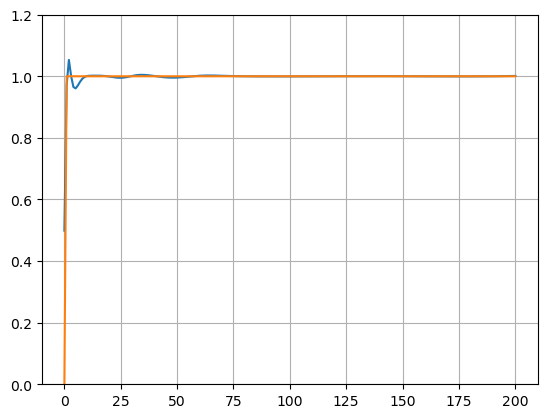

In [8]:
plt.plot(u_model[:,0])
plt.plot(ref_u[:,0])
plt.grid()
plt.ylim(0.0,1.2)

(-0.2, 1.0)

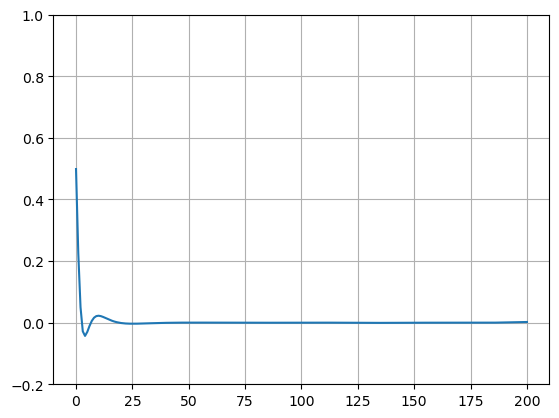

In [9]:
plt.plot(u_model[0])
plt.grid()
plt.ylim(-0.2,1.0)

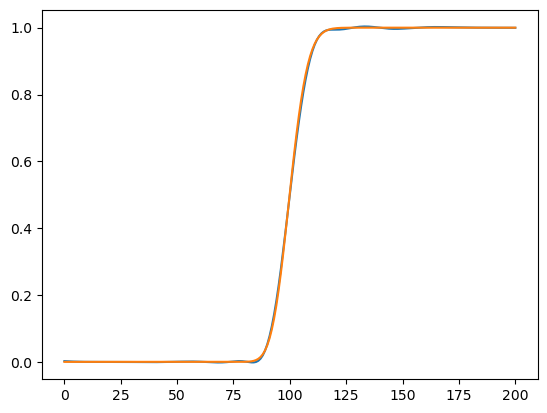

In [10]:
plt.plot(u_model[:,-1])
plt.plot(ref_u[:,-1])

In [12]:
save = True
load = False

save_path = "PINN_problem_2_model.pt"

if save:
    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "epoch": epoch,
        "loss_hist": loss_hist,
        "eval_hist": eval_hist,
        "seed": seed,
    }, save_path)

    
if load:

    model = PINN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=2.5e-3)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(
        optimizer, (0.9)**(1/12000)
    )
    
    checkpoint = torch.load(save_path, map_location=device)
    
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    
    start_epoch = checkpoint["epoch"] + 1
    loss_hist = checkpoint["loss_hist"]
    eval_hist = checkpoint["eval_hist"]

# Inverse

In [ ]:
%%time
import torch
import torch.nn as nn
from torchinfo import summary
import random
from scipy.stats import qmc
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)


# =========================================================
# Device
# =========================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =========================================================
# Physical parameters
# =========================================================
v0 = 0.213*805/86 * (0.8) 
D0 = 0.037*805/86**2 * (1.5) 
Nt = 200
Nx = 200
lambda_PDE = 1.0
lambda_data = 1000.0 

# Domain
x_min, x_max = 0.0, 1.0
t_min, t_max = 0.0, 1.0


t_data = torch.tensor(data_t, dtype=torch.float32, device=device).view(-1, 1)
u_data = torch.tensor(data_vals, dtype=torch.float32, device=device).view(-1, 1)
x_data = torch.full_like(t_data, x_max)

# =========================================================
# Trainable physical parameters (log-parameterization)
# =========================================================
log_v = nn.Parameter(torch.tensor(np.log(v0), dtype=torch.float32, device=device))
log_D = nn.Parameter(torch.tensor(np.log(D0), dtype=torch.float32, device=device))


def get_phys_params():
    v = torch.exp(log_v)
    D = torch.exp(log_D)
    return v, D


# =========================================================
# PINN architecture
# =========================================================
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 84),
            nn.Tanh(),
            nn.Linear(84, 84),
            nn.Tanh(),
            nn.Linear(84, 1)
        )

    def forward(self, x, t):
        xt = torch.cat([x, t], dim=1)
        return self.net(xt)

model_inv = PINN().to(device)
summary(model_inv, input_size=[(1,1), (1,1)], device=device)
trainable_params = sum(
    p.numel() for p in model_inv.parameters() if p.requires_grad
)
print(f"Trainable parameters: {trainable_params:,}")


# =========================================================
# PDE residual
# =========================================================
def pde_residual(x, t, model):
    x.requires_grad_(True)
    t.requires_grad_(True)

    v, D = get_phys_params()

    u = model(x, t)

    u_x = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)[0]
    u_t = torch.autograd.grad(u, t, torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True)[0]

    return u_t + v * u_x - D * u_xx

def rbc_res(x, t, model):
    x.requires_grad_(True)
    t.requires_grad_(True)

    u = model(x, t)

    u_x = torch.autograd.grad(
        u, x, grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    return u_x


    
# =========================================================
# Loss function
# =========================================================
def compute_loss(
    x_pde, t_pde,
    x_ic, t_ic, u_ic_true,
    x_bc_l, t_bc_l, u_bc_l_true,
    x_bc_r, t_bc_r, u_bc_r_true,
    x_data, t_data, u_data,
    model
):
    pde_res = pde_residual(x_pde, t_pde, model)
   
    loss_pde =  torch.mean(pde_res**2)

    loss_ic = torch.mean((model(x_ic, t_ic) - u_ic_true)**2)
    loss_bc_l = torch.mean((model(x_bc_l, t_bc_l) - u_bc_l_true)**2)
    loss_bc_r = torch.mean((rbc_res(x_bc_r, t_bc_r, model) - u_bc_r_true)**2)

    u_pred = model(x_data, t_data)
    loss_data = torch.mean((u_pred - u_data)**2)

    total_loss = lambda_PDE *loss_pde + loss_ic + loss_bc_l + loss_bc_r + lambda_data * loss_data

    return total_loss, loss_pde, loss_ic, 10*loss_bc_l, loss_bc_r,  loss_data
# =========================================================
# Training points
# =========================================================
N_pde, N_ic, N_bc = 20000, 500, 1000

def rand_uniform(n, a, b):
    return (a + (b - a) * torch.rand(n, 1)).to(device)




t_ic = torch.full((N_ic,1), t_min, device=device)
u_ic_true = torch.zeros_like(t_ic)

x_bc_l = torch.full((N_bc//2,1), x_min, device=device)
u_bc_l_true = torch.ones_like(x_bc_l)

x_bc_r = torch.full((N_bc//2,1), x_max, device=device)
u_bc_r_true = torch.zeros_like(x_bc_r)

# =========================================================
# Evaluation grid
# =========================================================
x_eval = np.linspace(x_min, x_max, Nx+1)
t_eval = np.linspace(t_min, t_max, Nt+1)

X_eval, T_eval = np.meshgrid(x_eval, t_eval)
Xf = X_eval.flatten().reshape(-1,1)
Tf = T_eval.flatten().reshape(-1,1)

Xf_t = torch.tensor(Xf, dtype=torch.float32, device=device)
Tf_t = torch.tensor(Tf, dtype=torch.float32, device=device)

@torch.no_grad()
def eval_mse(model):
    u_pred = model(Xf_t, Tf_t).cpu().numpy().flatten()
    return np.mean((u_pred - ref_u.flatten())**2)

# =========================================================
# Training
# =========================================================
epochs = 1250000
optimizer = torch.optim.Adam(
    list(model_inv.parameters()) + [log_v, log_D],
    lr=2.5e-3
)

scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, (0.9)**(1/12000))


loss_hist_inv, eval_hist_inv = [], []
losses_hist_inv = []
v_hist, D_hist = [], []

def lhs_timespace(N, x_min, x_max, t_min, t_max, seed):
    sampler = qmc.LatinHypercube(d=2, seed=seed)
    sample = sampler.random(N)

    sample[:, 0] = x_min + (x_max - x_min) * sample[:, 0]
    sample[:, 1] = t_min + (t_max - t_min) * sample[:, 1]

    x = torch.tensor(sample[:, 0:1], dtype=torch.float32, device=device)
    t = torch.tensor(sample[:, 1:2], dtype=torch.float32, device=device)

    return x, t

log_v.requires_grad_(False)
log_D.requires_grad_(False)

pretrain_epochs = 30000

for epoch in range(epochs):

    if epoch == pretrain_epochs:
        log_v.requires_grad_(True)
        log_D.requires_grad_(True)
        print(">>> Unlocking v and D")
    
    optimizer.zero_grad()
    if epoch==0:
        x_pde, t_pde = lhs_timespace(N_pde, x_min, x_max, t_min, t_max, seed+epoch)
        x_ic = rand_uniform(N_ic, x_min, x_max)
        t_bc_l = rand_uniform(N_bc//2, t_min, t_max)
        t_bc_r = rand_uniform(N_bc//2, t_min, t_max)

    total_loss, lpde, lic, lbl, lbr, ldata = compute_loss(
        x_pde, t_pde,
        x_ic, t_ic, u_ic_true,
        x_bc_l, t_bc_l, u_bc_l_true,
        x_bc_r, t_bc_r, u_bc_r_true,
        x_data, t_data, u_data,
        model_inv
    )

    total_loss.backward()
    optimizer.step()
    scheduler.step()
    loss_hist_inv.append(total_loss.item())

    
    e = eval_mse(model_inv)
    eval_hist_inv.append(e)
    losses_hist_inv.append([lpde.item(), lic.item(), lbl.item(), lbr.item()])
    v_est, D_est = get_phys_params()
    v_hist.append(v_est.item())
    D_hist.append(D_est.item())
    
    if epoch%100 == 0:
        
        print(
            f"Epoch {epoch:4d}, "
            f"{lpde.item():.3e}, {lic.item():.3e}, "
            f"{lbl.item():.3e}, {lbr.item():.3e} | "
            f"{ldata.item():.3e}, {v_est.item():.4e}, {D_est.item():.4e} | "
            f"Total {total_loss.item():.3e} | Eval MSE {e:.3e}"
        )

Using device: cuda
Trainable parameters: 7,477
Epoch    0, 4.240e-03, 2.185e-05, 8.735e+00, 3.303e-04 | 4.005e-01, 1.5950e+00, 6.0408e-03 | Total 4.014e+02 | Eval MSE 3.406e-01
Epoch  100, 4.813e-01, 2.085e-02, 1.521e+00, 2.746e-01 | 4.255e-02, 1.5950e+00, 6.0408e-03 | Total 4.348e+01 | Eval MSE 8.083e-02
Epoch  200, 2.426e-01, 3.111e-02, 1.264e+00, 3.923e-01 | 3.986e-02, 1.5950e+00, 6.0408e-03 | Total 4.065e+01 | Eval MSE 7.275e-02
Epoch  300, 5.259e-01, 5.050e-03, 9.114e-01, 4.212e-01 | 9.894e-03, 1.5950e+00, 6.0408e-03 | Total 1.094e+01 | Eval MSE 4.162e-02
Epoch  400, 6.519e-01, 3.966e-03, 8.245e-01, 6.641e-01 | 4.047e-03, 1.5950e+00, 6.0408e-03 | Total 5.449e+00 | Eval MSE 3.391e-02
Epoch  500, 5.217e-01, 4.680e-03, 5.620e-01, 8.436e-01 | 1.478e-03, 1.5950e+00, 6.0408e-03 | Total 2.904e+00 | Eval MSE 2.356e-02
Epoch  600, 5.212e-01, 5.318e-03, 4.825e-01, 9.801e-01 | 6.414e-04, 1.5950e+00, 6.0408e-03 | Total 2.196e+00 | Eval MSE 2.083e-02
Epoch  700, 5.150e-01, 7.074e-03, 4.339e-01

In [ ]:
plt.semilogy(loss_hist_inv)

In [ ]:
save = True
load = False

save_path_inv = "PINN_problem_2_model_inverse.pt"

if save:
    torch.save({
        "model_state_dict": model_inv.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "epoch": epoch,
        "loss_hist": loss_hist_inv,
        "eval_hist": eval_hist_inv,
        "seed": seed,
    }, save_path_inv)

    
if load:

    model_inv = PINN().to(device)
    optimizer = torch.optim.Adam(model_inv.parameters(), lr=2.5e-3)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(
        optimizer, (0.9)**(1/12000)
    )
    
    checkpoint = torch.load(save_path_inv, map_location=device)
    
    model_inv.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    
    start_epoch = checkpoint["epoch"] + 1
    loss_hist_inv = checkpoint["loss_hist"]
    eval_hist_inv = checkpoint["eval_hist"]

In [ ]:
plt.semilogy(eval_hist)
plt.semilogy(eval_hist_inv)

In [ ]:
u_pred = model(Xf_t, Tf_t).detach().cpu().numpy().reshape((len(x_eval)),len(t_eval))
u_pred_inv = model_inv(Xf_t, Tf_t).detach().cpu().numpy().reshape((len(x_eval)),len(t_eval))
np.save('PINN_problem_2_fwd_output.npy', u_pred)
np.save('PINN_problem_2_inv_output.npy', u_pred_inv)

In [ ]:
est_params = np.array([v_est.item(),D_est.item()])
np.save('PINN_problem_2_est_params.npy', est_params)